<a href="https://colab.research.google.com/github/BuildBrickByBrick/INNER-HELL-Psychological--Survival--Architect-game/blob/main/Exploratory_Data_Analysis_of_Video_Game_Sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!
Dataset created successfully!

First 5 rows of the dataset:
   Rank                      Name Platform  Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  

Last 5 rows of the dataset:
     Rank                            Name Platform  Yea

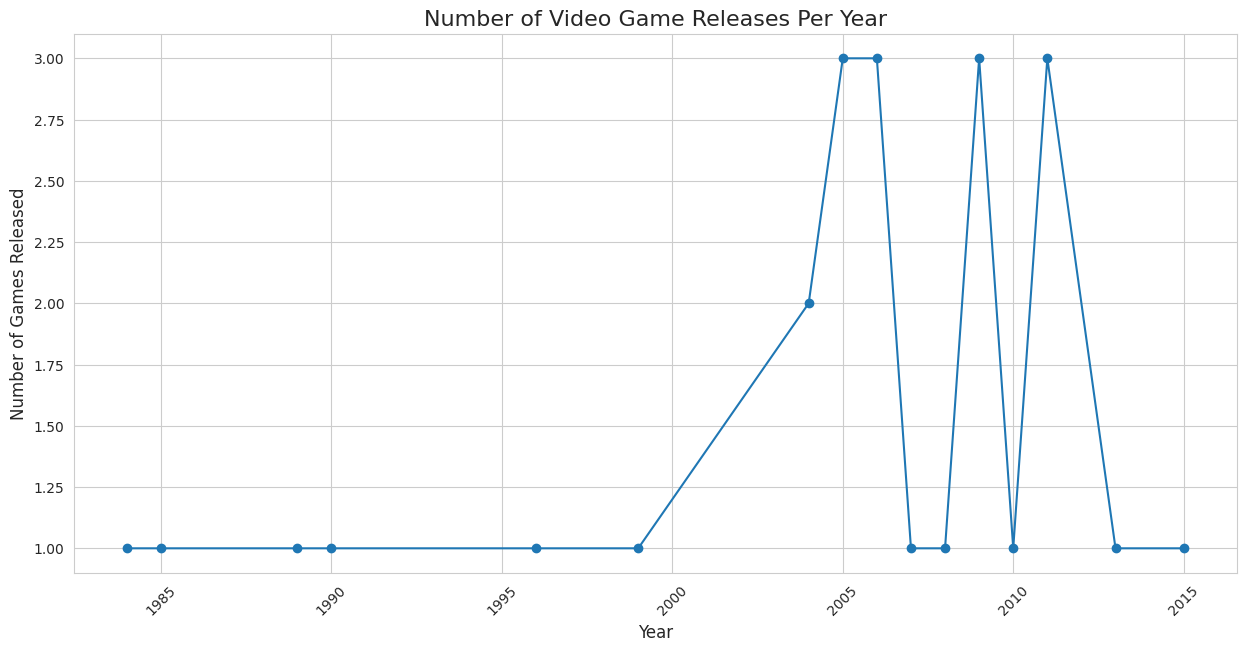

/tmp/ipykernel_2609/132477980.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.index, y=top_categories.values, palette ='viridis')


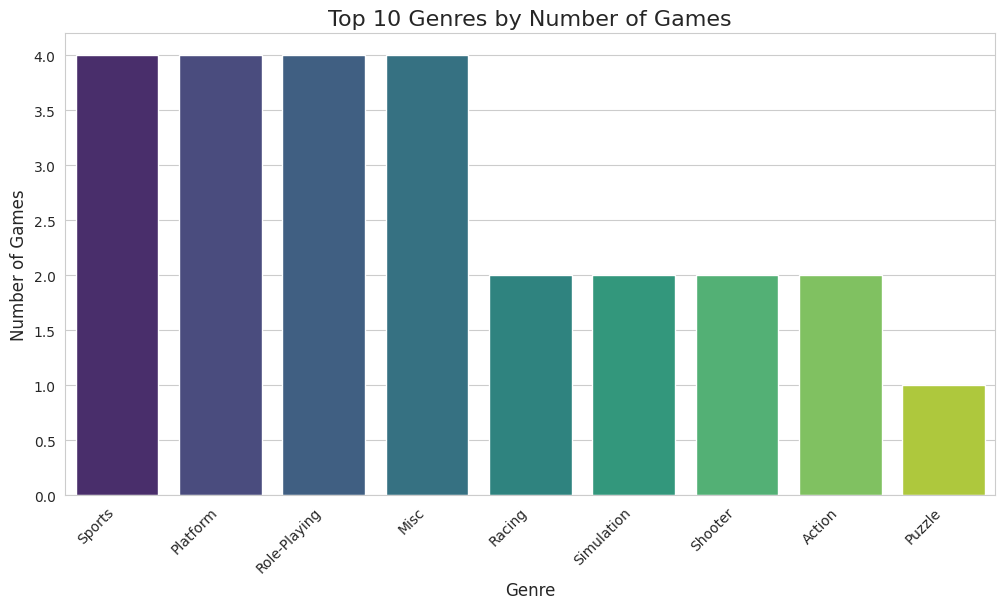

/tmp/ipykernel_2609/132477980.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.index, y=top_categories.values, palette ='viridis')


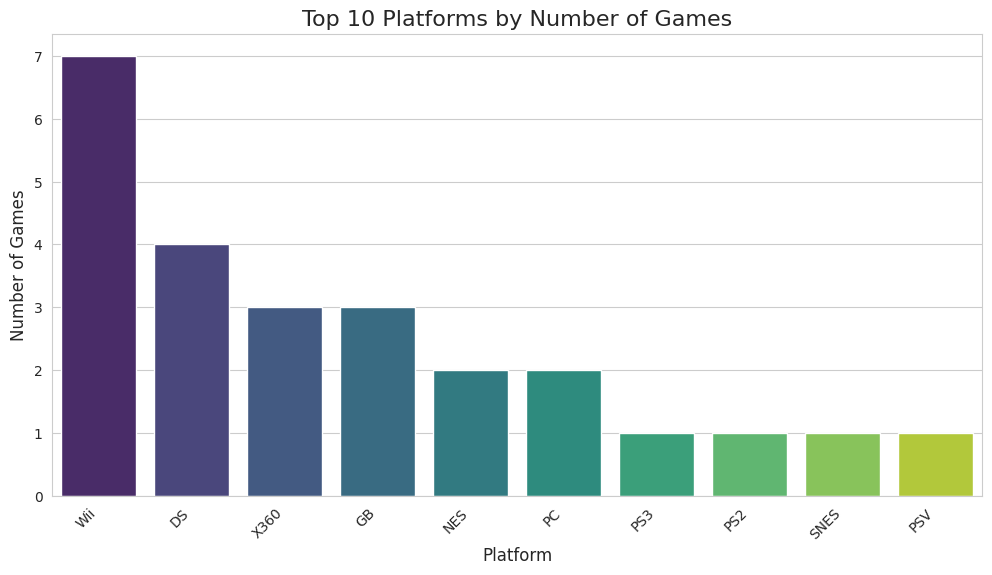

/tmp/ipykernel_2609/132477980.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.index, y=top_categories.values, palette ='viridis')


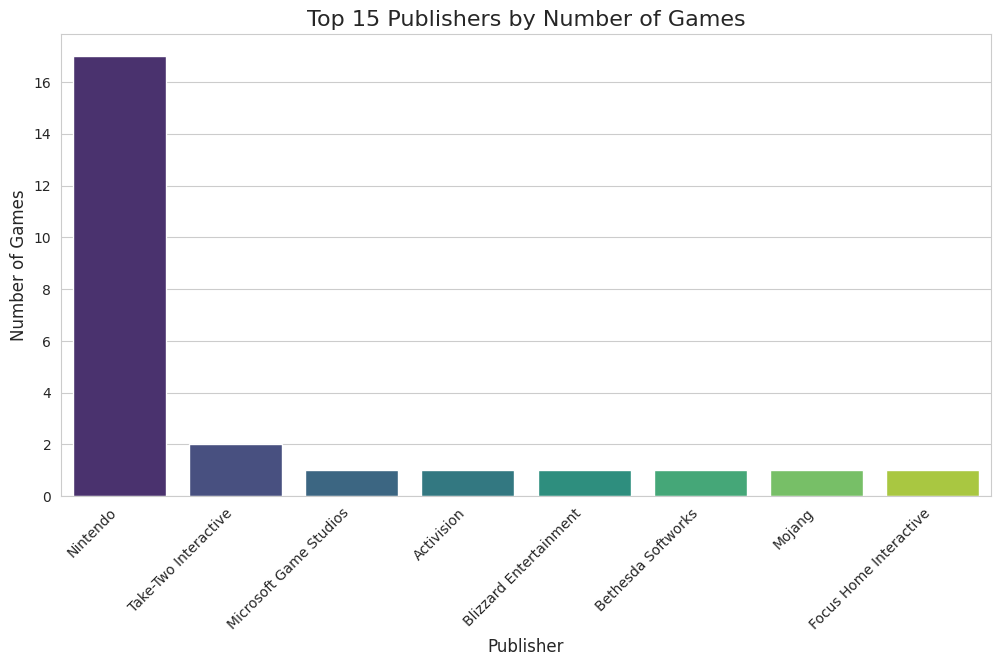


Are 'Global_Sales' and calculated sales columns approximately equal? False


/tmp/ipykernel_2609/132477980.py:233: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Global_Sales', y='Name', data=top_games, palette='rocket')


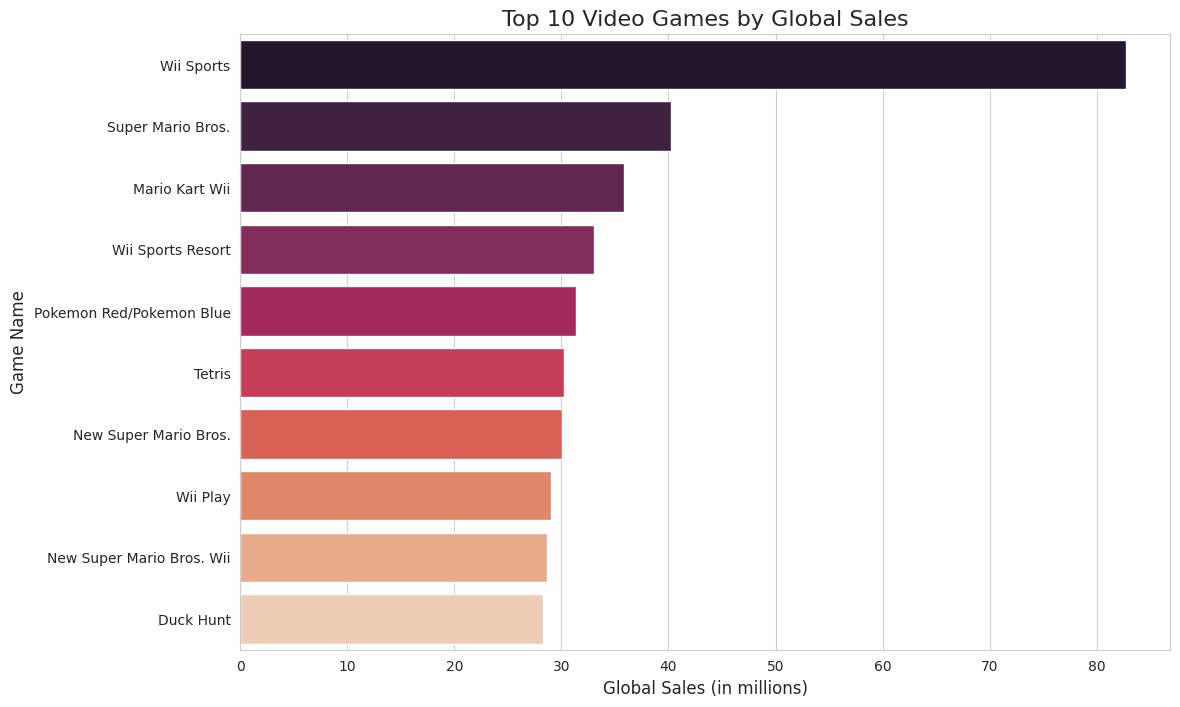


Total Sales by Genre (in millions):
              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
Genre                                                                
Action           16.44      9.67      1.38        14.71         42.21
Misc             33.75     28.61      7.33         7.00         76.70
Platform         67.83     23.62     21.55         6.48        119.48
Puzzle           23.20      2.26      4.22         0.58         30.26
Racing           25.66     20.45      7.92         5.23         59.24
Role-Playing     25.37     24.14     17.52         5.42         72.45
Shooter          35.96      4.91      0.41         1.79         43.07
Simulation        9.07     11.01      1.93         2.75         24.77
Sports           75.27     56.65     13.18        15.36        160.46


/tmp/ipykernel_2609/132477980.py:265: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_sales_df_sorted.index, y=genre_sales_df_sorted.values, palette='cubehelix')


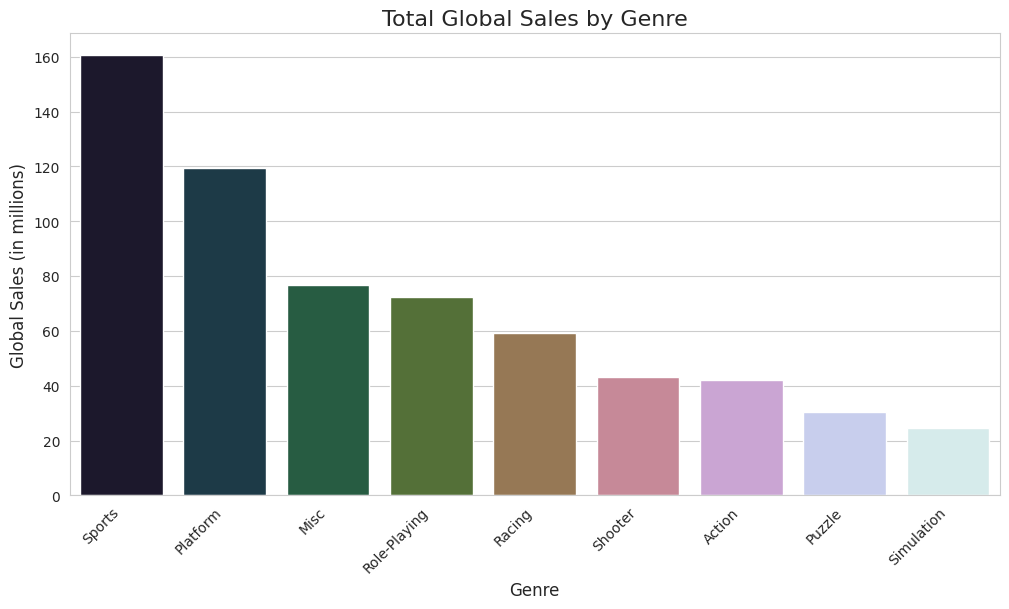


Market Share of Top 5 Publishers:
                Publisher  Market_Share_%
0                Nintendo       83.707686
1    Take-Two Interactive        6.714495
2  Microsoft Game Studios        3.470985
3              Activision        2.347926
4  Blizzard Entertainment        1.453932


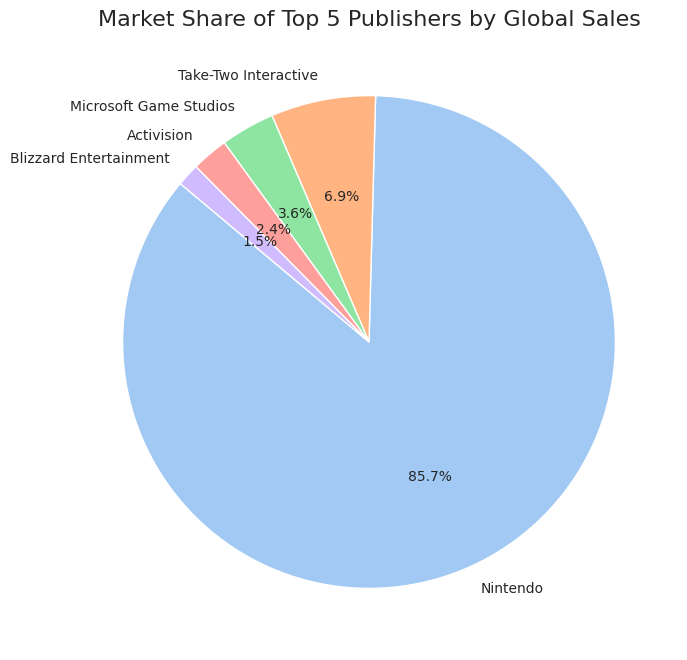


Top Genre in North America: Sports with $75.27M in sales.
Top Genre in Europe: Sports with $56.65M in sales.
Top Genre in Japan: Platform with $21.55M in sales.


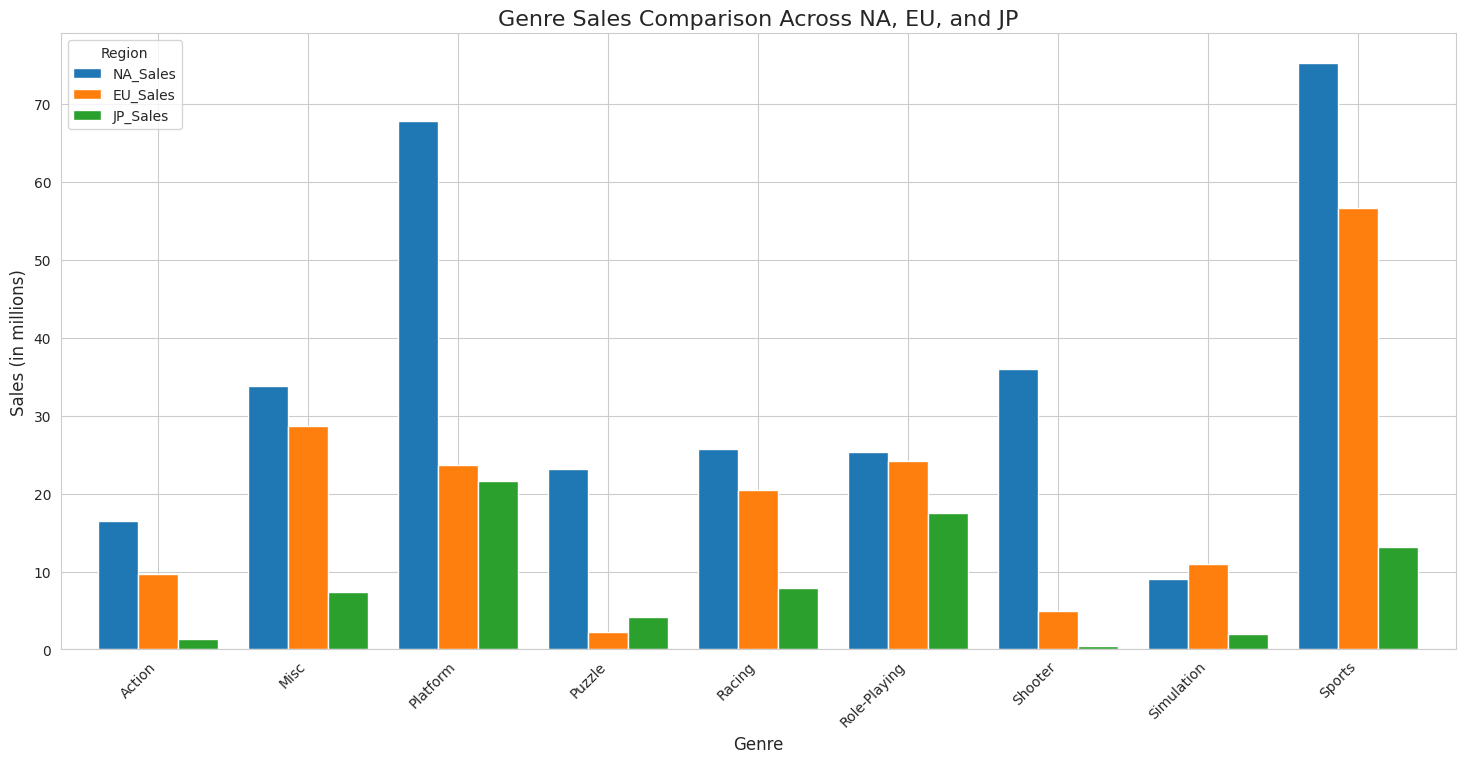

In [1]:
# -*- coding: utf-8 -*-
"""
# Exploratory Data Analysis (EDA) of Video Game Sales

This project conducts an exploratory data analysis on a video game sales dataset.
The goal is to explore the data, uncover insights, and practice fundamental data analysis
techniques using Python's most popular libraries: Pandas and NumPy.

### Project Structure:
1.  **Introduction to EDA and the Dataset**
2.  **Setting up the Environment and Loading Data**
3.  **Data Cleaning and Preparation**
4.  **Exploratory Analysis and Visualization**
5.  **Answering Key Questions with Data**
"""

# =============================================================================
# Part 1: Introduction to EDA and the Dataset
# =============================================================================
#
# **What is Exploratory Data Analysis (EDA)?**
# EDA is the process of summarizing the main characteristics of a dataset, often
# with visual methods. It's a critical first step in any data analysis project.
# The goal is to understand the data, find patterns, spot anomalies, and check
# assumptions before performing more formal modeling or hypothesis testing.
#
# **About the Dataset:**
# The dataset we'll be using contains a list of video games with sales greater
# than 100,000 copies. It was generated by a scrape of vgchartz.com.
#
# **Columns:**
# - Rank: Ranking of overall sales
# - Name: The name of the game
# - Platform: Platform of the game's release (e.g., PS4, PC, X360)
# - Year: Year of the game's release
# - Genre: Genre of the game
# - Publisher: Publisher of the game
# - NA_Sales: Sales in North America (in millions)
# - EU_Sales: Sales in Europe (in millions)
# - JP_Sales: Sales in Japan (in millions)
# - Other_Sales: Sales in the rest of the world (in millions)
# - Global_Sales: Total worldwide sales (in millions)
#
# Let's begin!

# =============================================================================
# Part 2: Setting up the Environment and Loading Data
# =============================================================================

# Step 2.1: Import necessary libraries
# -------------------------------------
# We start by importing the libraries we'll need.
# - pandas: For data manipulation and analysis. We give it the alias 'pd'.
# - numpy: For numerical operations. We give it the alias 'np'.
# - matplotlib.pyplot: For creating static, animated, and interactive visualizations.
# - seaborn: A data visualization library based on matplotlib that provides a high-level interface.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

# Step 2.2: Create the dataset
# ----------------------------
# Instead of loading from a file or URL, we will create the DataFrame directly.
# This makes the script self-contained. A sample of the data is stored in a
# Python dictionary, which is then used to create the pandas DataFrame.

game_data = {
    'Rank': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 259, 498, 520, 1500, 16532],
    'Name': ['Wii Sports', 'Super Mario Bros.', 'Mario Kart Wii', 'Wii Sports Resort', 'Pokemon Red/Pokemon Blue', 'Tetris', 'New Super Mario Bros.', 'Wii Play', 'New Super Mario Bros. Wii', 'Duck Hunt', 'Nintendogs', 'Mario Kart DS', 'Pokemon Gold/Pokemon Silver', 'Wii Fit', 'Wii Fit Plus', 'Kinect Adventures!', 'Grand Theft Auto V', 'Grand Theft Auto: San Andreas', 'Super Mario World', 'Brain Age: Train Your Brain in Minutes a Day', 'Call of Duty: Modern Warfare 3', 'World of Warcraft', 'The Elder Scrolls V: Skyrim', 'Minecraft', 'Farming Simulator 2016'],
    'Platform': ['Wii', 'NES', 'Wii', 'Wii', 'GB', 'GB', 'DS', 'Wii', 'Wii', 'NES', 'DS', 'DS', 'GB', 'Wii', 'Wii', 'X360', 'PS3', 'PS2', 'SNES', 'DS', 'X360', 'PC', 'X360', 'PC', 'PSV'],
    'Year': [2006, 1985, 2008, 2009, 1996, 1989, 2006, 2006, 2009, 1984, 2005, 2005, 1999, 2007, 2009, 2010, 2013, 2004, 1990, 2005, 2011, 2004, 2011, 2011, 2015],
    'Genre': ['Sports', 'Platform', 'Racing', 'Sports', 'Role-Playing', 'Puzzle', 'Platform', 'Misc', 'Platform', 'Shooter', 'Simulation', 'Racing', 'Role-Playing', 'Sports', 'Sports', 'Misc', 'Action', 'Action', 'Platform', 'Misc', 'Shooter', 'Role-Playing', 'Role-Playing', 'Misc', 'Simulation'],
    'Publisher': ['Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Nintendo', 'Microsoft Game Studios', 'Take-Two Interactive', 'Take-Two Interactive', 'Nintendo', 'Nintendo', 'Activision', 'Blizzard Entertainment', 'Bethesda Softworks', 'Mojang', 'Focus Home Interactive'],
    'NA_Sales': [41.49, 29.08, 15.85, 15.75, 11.27, 23.2, 11.38, 14.03, 14.59, 26.93, 9.07, 9.81, 9.0, 8.94, 9.09, 14.97, 7.01, 9.43, 12.78, 4.75, 9.03, 0.07, 5.03, 0.0, 0.0],
    'EU_Sales': [29.02, 3.58, 12.88, 11.01, 8.89, 2.26, 9.23, 9.2, 7.06, 0.63, 11.0, 7.57, 6.18, 8.03, 8.59, 4.94, 9.27, 0.4, 3.75, 9.26, 4.28, 6.21, 2.86, 5.21, 0.01],
    'JP_Sales': [3.77, 6.81, 3.79, 3.28, 10.22, 4.22, 6.5, 2.93, 4.7, 0.28, 1.93, 4.13, 7.2, 3.6, 2.53, 0.24, 0.97, 0.41, 3.54, 4.16, 0.13, 0.0, 0.1, 0.0, 0.0],
    'Other_Sales': [8.46, 0.77, 3.31, 2.96, 1.0, 0.58, 2.9, 2.85, 2.26, 0.47, 2.75, 1.92, 0.71, 2.15, 1.79, 1.67, 4.14, 10.57, 0.55, 2.05, 1.32, 2.86, 0.85, 0.43, 0.0],
    'Global_Sales': [82.74, 40.24, 35.82, 33.0, 31.37, 30.26, 30.01, 29.02, 28.62, 28.31, 24.76, 23.42, 23.1, 22.72, 22.0, 21.82, 21.4, 20.81, 20.61, 20.22, 14.76, 9.14, 8.84, 5.64, 0.01]
}

df = pd.DataFrame(game_data)
print("Dataset created successfully!")


# Step 2.3: Initial Data Inspection
# ---------------------------------
# Now that we have our data in a DataFrame, let's take a first look at it.
# This helps us understand its structure, size, and the type of data it contains.

# .head() shows the first 5 rows of the DataFrame.
print("\nFirst 5 rows of the dataset:")
print(df.head())

# .tail() shows the last 5 rows.
print("\nLast 5 rows of the dataset:")
print(df.tail())

# .shape returns a tuple representing the dimensionality of the DataFrame (rows, columns).
print(f"\nDataset shape: {df.shape[0]} rows and {df.shape[1]} columns")

# .info() provides a concise summary of the DataFrame.
# This includes the index dtype and columns, non-null values, and memory usage.
# It's great for quickly checking for missing values and data types.
print("\nDataset Information:")
df.info()

# .describe() generates descriptive statistics.
# For numeric columns, it includes count, mean, std, min, max, and percentiles.
# This is a great way to get a feel for the distribution of the numerical data.
print("\nDescriptive Statistics for Numerical Columns:")
print(df.describe())

# For object (string) columns, it includes count, unique, top, and frequency.
print("\nDescriptive Statistics for Categorical Columns:")
print(df.describe(include=['object']))


# =============================================================================
# Part 3: Data Cleaning and Preparation
# =============================================================================
#
# Real-world data is often messy. It can have missing values, incorrect data types,
# or inconsistencies. We need to clean it before we can analyze it.

# Step 3.1: Handling Missing Values
# ---------------------------------
# Let's check for missing values in our dataset.

# .isnull().sum() counts the number of missing (NaN) values in each column.
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# For this analysis, we can remove the rows with missing values.
# For 'Year' and 'Publisher', these rows constitute a small fraction of the total dataset.
# The .dropna() method removes rows or columns with missing values.
# The 'subset' parameter allows us to specify which columns to consider.
df_cleaned = df.dropna(subset=['Year', 'Publisher'])

# Let's verify that the missing values have been handled.
print("\nMissing values after cleaning:")
print(df_cleaned.isnull().sum())
print(f"\nShape of DataFrame after dropping rows: {df_cleaned.shape}")

# Step 3.2: Correcting Data Types
# -------------------------------
# The 'Year' column is currently a float64, but it should be an integer
# since it represents a year.

# We use the .astype() method to change the data type of a column.
df_cleaned['Year'] = df_cleaned['Year'].astype(int)

print("\nData types after correction:")
print(df_cleaned.info())


# Now that our data is clean, we can start exploring it to find insights.
# We will use visualizations to make patterns more obvious.

# Let's set a style for our plots for better aesthetics.
sns.set_style("whitegrid")

# Step 4.1: Analyzing Game Releases Over the Years
# ------------------------------------------------
# How many games were released each year?

# We can use .value_counts() to count the occurrences of each year.
# .sort_index() sorts the result by the year.
yearly_releases = df_cleaned['Year'].value_counts().sort_index()

plt.figure(figsize=(15, 7)) # Set the figure size for better readability
plt.plot(yearly_releases.index, yearly_releases.values, marker='o', linestyle='-')
plt.title('Number of Video Game Releases Per Year', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Games Released', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# **Observation:** We can see a significant rise in game releases from the late 90s,
# peaking around 2008-2009, and then a decline. This could be due to the rise of
# mobile gaming or changes in the industry.

# Step 4.2: Top Genres, Platforms, and Publishers
# ------------------------------------------------
# Which genres, platforms, and publishers are the most common?

# We'll create a function to avoid repeating code for plotting.
def plot_top_categories(column_name, top_n=10):
    """
    This function takes a column name and plots the top N categories.
    """
    plt.figure(figsize=(12, 6))
    # Get the value counts and select the top N
    top_categories = df_cleaned[column_name].value_counts().nlargest(top_n)
    sns.barplot(x=top_categories.index, y=top_categories.values, palette ='viridis')
    plt.title(f'Top {top_n} {column_name}s by Number of Games', fontsize=16)
    plt.xlabel(column_name, fontsize=12)
    plt.ylabel('Number of Games', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.show()

plot_top_categories('Genre')
plot_top_categories('Platform')
plot_top_categories('Publisher', top_n=15)

# **Observations:**
# - 'Action' is the most frequent genre.
# - 'PS2' and 'DS' are the platforms with the most game releases in this dataset.
# - 'Electronic Arts' is the publisher with the most games.

# Step 4.3: Analyzing Sales Data
# ------------------------------
# Let's look at which games and genres are the highest-selling.

# Let's create a new column for 'Total_Sales' using NumPy.
# Although we have 'Global_Sales', summing the regional sales is a good practice
# to ensure data consistency and to demonstrate NumPy.
sales_columns = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
df_cleaned['Calculated_Global_Sales'] = np.sum(df_cleaned[sales_columns], axis=1)

# Let's check if our calculated sales match the 'Global_Sales' column.
# We can use np.allclose() to compare floating-point arrays for approximate equality.
are_sales_equal = np.allclose(df_cleaned['Global_Sales'], df_cleaned['Calculated_Global_Sales'])
print(f"\nAre 'Global_Sales' and calculated sales columns approximately equal? {are_sales_equal}")

# Top 10 Games by Global Sales
top_games = df_cleaned.nlargest(10, 'Global_Sales')

plt.figure(figsize=(12, 8))
sns.barplot(x='Global_Sales', y='Name', data=top_games, palette='rocket')
plt.title('Top 10 Video Games by Global Sales', fontsize=16)
plt.xlabel('Global Sales (in millions)', fontsize=12)
plt.ylabel('Game Name', fontsize=12)
plt.show()

# **Observation:** 'Wii Sports' is by far the best-selling game.

# Step 4.4: Sales by Genre
# ------------------------
# Which genres generate the most sales?

# We will use a dictionary to store the total sales for each region by genre.
# This demonstrates a practical use of Python dictionaries.
genre_sales = {}
regions = ['NA_Sales', 'EU_Sales','JP_Sales', 'Other_Sales', 'Global_Sales']

# We use .groupby() to group the DataFrame by the 'Genre' column.
# Then we can perform an aggregation, like .sum(), on the sales columns.
grouped_by_genre = df_cleaned.groupby('Genre')

# Let's calculate the sum of sales for each region.
genre_sales_df = grouped_by_genre[regions].sum()

# Let's see the resulting DataFrame.
print("\nTotal Sales by Genre (in millions):")
print(genre_sales_df)

# Now, let's visualize the global sales by genre.
genre_sales_df_sorted = genre_sales_df['Global_Sales'].sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=genre_sales_df_sorted.index, y=genre_sales_df_sorted.values, palette='cubehelix')
plt.title('Total Global Sales by Genre', fontsize=16)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Global Sales (in millions)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

# **Observation:** While 'Action' games are the most numerous, 'Platform' and 'Shooter'
# games also have very high total sales.

# =============================================================================
# Part 5: Answering Key Questions with Data
# =============================================================================
#
# Let's use our skills to answer some more specific questions.

# Question 1: What are the market share percentages of the top 5 publishers globally?
# -----------------------------------------------------------------------------------
publisher_sales = df_cleaned.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False)
top_5_publishers = publisher_sales.head(5)
total_global_sales = df_cleaned['Global_Sales'].sum()

# We can use a dictionary to store the market share.
market_share = {
    'Publisher': top_5_publishers.index,
    'Market_Share_%': (top_5_publishers.values / total_global_sales) * 100
}

market_share_df = pd.DataFrame(market_share)
print("\nMarket Share of Top 5 Publishers:")
print(market_share_df)

# Let's visualize this with a pie chart.
plt.figure(figsize=(10, 8))
plt.pie(top_5_publishers, labels=top_5_publishers.index, autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('pastel'))
plt.title('Market Share of Top 5 Publishers by Global Sales', fontsize=16)
plt.ylabel('') # Hide the y-label
plt.show()

# **Observation:** Nintendo is the dominant publisher in terms of global sales.

# Question 2: How do genre preferences differ across regions (NA, EU, JP)?
# -------------------------------------------------------------------------
# We already have the sales data grouped by genre. Let's find the top genre for each region.

# Using NumPy's argmax to find the index of the max value in each column.
top_genre_na = genre_sales_df['NA_Sales'].idxmax()
top_genre_eu = genre_sales_df['EU_Sales'].idxmax()
top_genre_jp = genre_sales_df['JP_Sales'].idxmax()

print(f"\nTop Genre in North America: {top_genre_na} with ${genre_sales_df.loc[top_genre_na, 'NA_Sales']:.2f}M in sales.")
print(f"Top Genre in Europe: {top_genre_eu} with ${genre_sales_df.loc[top_genre_eu, 'EU_Sales']:.2f}M in sales.")
print(f"Top Genre in Japan: {top_genre_jp} with ${genre_sales_df.loc[top_genre_jp, 'JP_Sales']:.2f}M in sales.")

# Let's visualize the comparison.
genre_sales_df[ ['NA_Sales', 'EU_Sales', 'JP_Sales'] ].plot(kind='bar', figsize=(18, 8), width=0.8)
plt.title('Genre Sales Comparison Across NA, EU, and JP', fontsize=16)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Sales (in millions)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Region')
plt.show()

# **Observation:** While 'Action' games sell well in North America and Europe,
# 'Role-Playing' games are significantly more popular in Japan. This highlights
# regional differences in market preferences.

# =============================================================================
# Conclusion of the EDA Project
# =============================================================================
#
# In this analysis, we have:
# 1. Loaded and inspected a real-world dataset.
# 2. Cleaned the data by handling missing values and correcting data types.
# 3. Performed exploratory analysis using pandas and NumPy.
# 4. Created visualizations with Matplotlib and Seaborn to understand trends.
# 5. Answered specific questions about the video game market.
#
# This project serves as a practical introduction to the workflow of a data analyst.
# The next steps could involve more advanced statistical analysis, predictive modeling
# (e.g., predicting a game's sales), or more detailed feature engineering.
#
# End of the EDA Project.